# Fairness Analysis

All trained models scored with `results_by_group` on `X_test_prep.csv` (no race/sex/ethnicity as inputs).

Includes Logistic Regression, Decision Tree, Random Forests, XGBoost, and the Keras neural network.

**Story:** Is there already a gap in the data? Does each model keep it, shrink it, or make it worse?


In [1]:
import sys
sys.path.append('../scripts')
import os
os.environ.setdefault('KERAS_BACKEND', 'torch')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load sklearn / xgboost models BEFORE importing keras (avoids a segfault on this machine).
X_test = pd.read_csv('../data/features/X_test_prep.csv', index_col='row_id')
y_test = pd.read_csv('../data/features/y_test.csv', index_col='row_id')['is_approved']
protected = pd.read_csv('../data/features/protected_test.csv', index_col='row_id')

MODELS = {
  'Logistic Regression': joblib.load('../data/models/logistic_regression_model.joblib'),
  'Decision Tree': joblib.load('../data/models/decision_tree_model.joblib'),
  'RF Balanced': joblib.load('../data/models/random_forest_balanced.joblib'),
  'RF Imbalanced': joblib.load('../data/models/random_forest_classifier_imbalanced.joblib'),
  'RF Protected*': joblib.load('../data/models/random_forest_balanced_protected.joblib'),
  'XGBoost': joblib.load('../data/models/xgboost_model.joblib'),
}
import keras
from fairness_eval import results_by_group
MODELS['Neural Network'] = keras.models.load_model('../data/models/neural_network_model.keras')
print('Loaded', len(MODELS), 'models')
print('* RF Protected was trained on the same 97 non-protected features')


Loaded 7 models
* RF Protected was trained on the same 97 non-protected features


In [2]:
def run_all(group):
  return {name: results_by_group(model, X_test, y_test, group) for name, model in MODELS.items()}

def simple_compare(tables, group_col, group_a, group_b, title):
  def val(table, name, col):
    return float(table.loc[table[group_col] == name, col].iloc[0])
  first = next(iter(tables.values()))
  labels = ['True rate\n(in the data)'] + [f'{name}\napproval rate' for name in tables]
  a_vals = [val(first, group_a, 'approval_rate')]
  b_vals = [val(first, group_b, 'approval_rate')]
  for table in tables.values():
    a_vals.append(val(table, group_a, 'predicted_approval_rate'))
    b_vals.append(val(table, group_b, 'predicted_approval_rate'))
  x = np.arange(len(labels)); width = 0.38
  fig, ax = plt.subplots(figsize=(max(11, 1.8 * len(labels)), 5.5))
  bars_a = ax.bar(x - width/2, a_vals, width, label=group_a, color='#4C78A8')
  bars_b = ax.bar(x + width/2, b_vals, width, label=group_b, color='#F58518')
  for bars in (bars_a, bars_b):
    for bar in bars:
      h = bar.get_height()
      ax.text(bar.get_x()+bar.get_width()/2, h+0.015, f'{h:.0%}', ha='center', va='bottom', fontsize=9, fontweight='bold')
  for i,(va,vb) in enumerate(zip(a_vals,b_vals)):
    ax.text(i, max(va,vb)+0.09, f'gap {vb-va:+.0%}', ha='center', fontsize=9, color='#B35C00')
  ax.set_ylim(0,1.2); ax.set_ylabel('Approval rate'); ax.set_xticks(x)
  ax.set_xticklabels(labels, fontsize=8); ax.set_title(title, fontsize=14, fontweight='bold')
  ax.legend(loc='upper right'); plt.tight_layout(); plt.show()


## Race — Black vs White


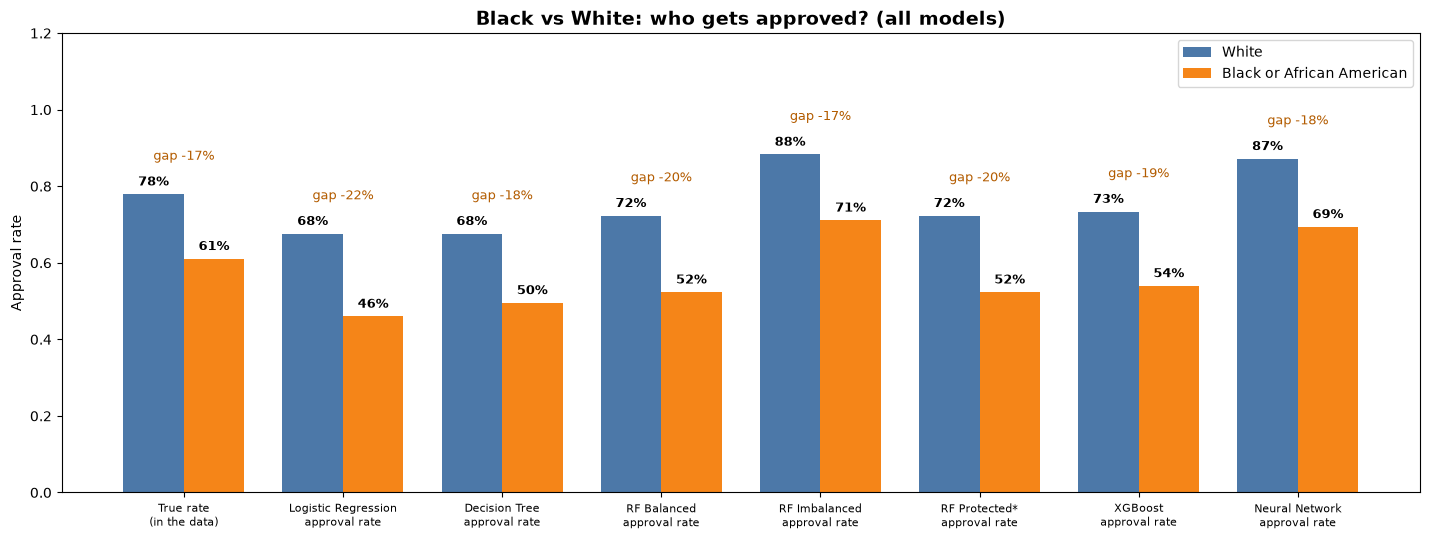

In [3]:
race_tables = run_all(protected['applicant_race_1'])

simple_compare(
  race_tables, 'applicant_race_1',
  'White', 'Black or African American',
  'Black vs White: who gets approved? (all models)',
)


## Sex — Female vs Male


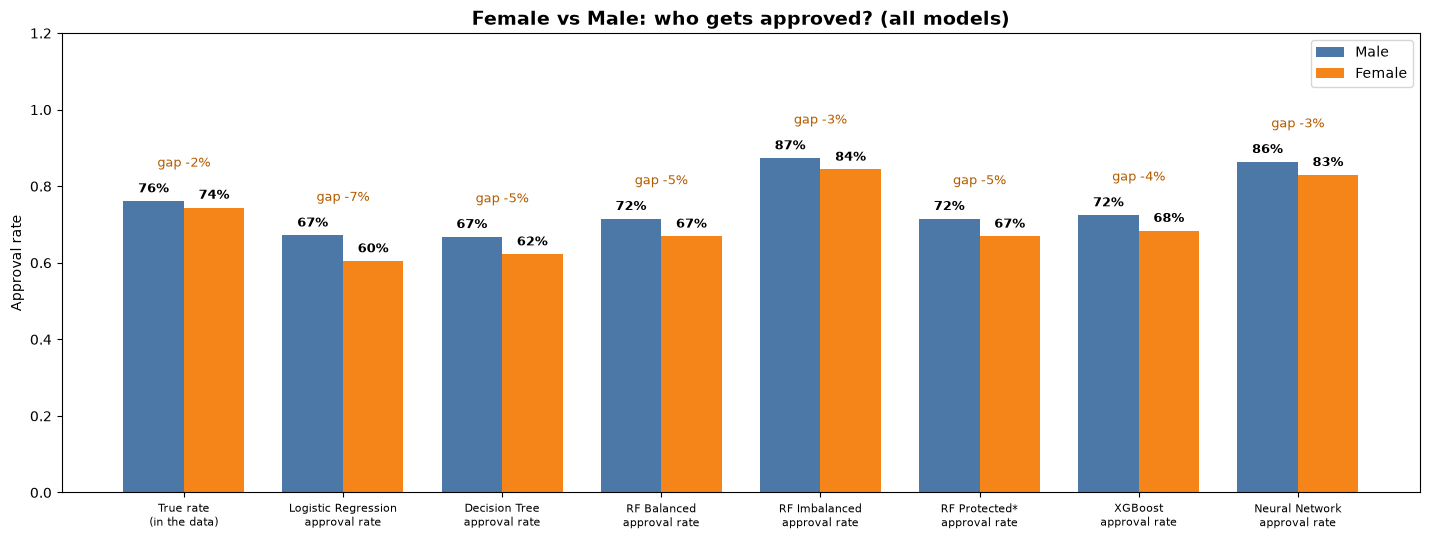

In [4]:
sex_tables = run_all(protected['applicant_sex'])

simple_compare(
  sex_tables, 'applicant_sex',
  'Male', 'Female',
  'Female vs Male: who gets approved? (all models)',
)


## Ethnicity — Hispanic vs Not Hispanic


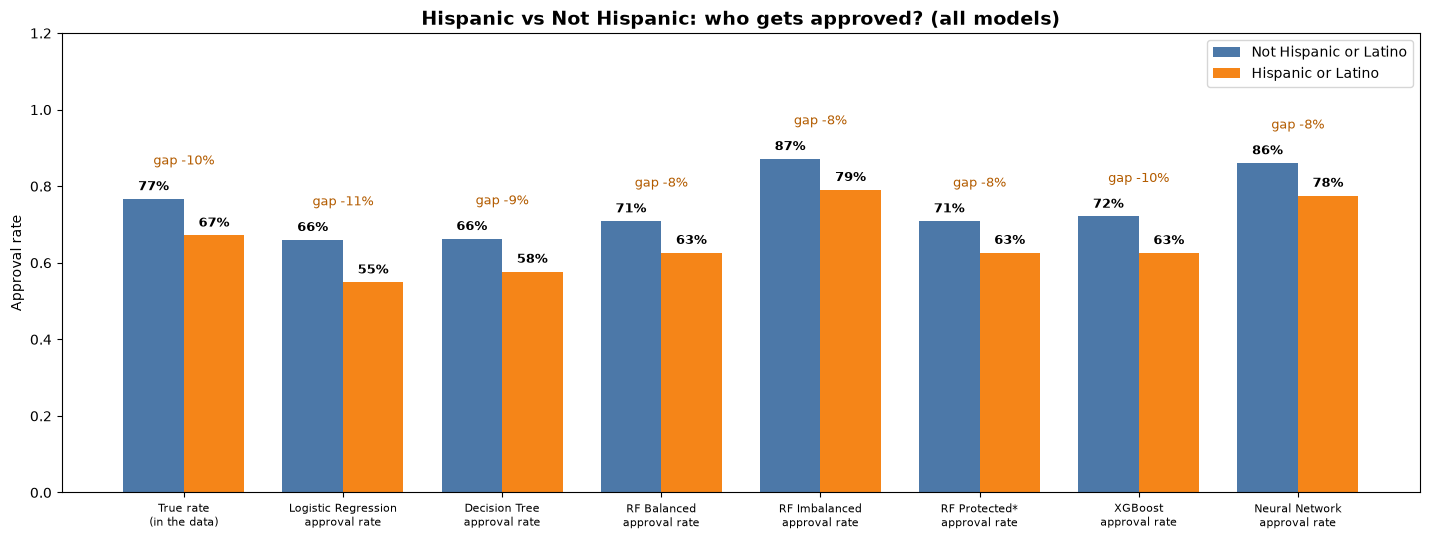

In [5]:
eth_tables = run_all(protected['applicant_ethnicity'])

simple_compare(
  eth_tables, 'applicant_ethnicity',
  'Not Hispanic or Latino', 'Hispanic or Latino',
  'Hispanic vs Not Hispanic: who gets approved? (all models)',
)


## Model scorecard — performance + fairness

Two charts to pick a model using **both** overall metrics and the Black–White approval gap.

- **Performance chart:** accuracy, approved F1, denied F1, macro F1, AUC-ROC
- **Fairness chart:** Black − White gaps (closer to 0 is fairer)


In [6]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from fairness_eval import _approval_probability

# Build one row per model: overall test metrics + Black-White gaps from race_tables
rows = []
for name, model in MODELS.items():
  scores = _approval_probability(model, X_test)
  pred = (scores >= 0.5).astype(int)
  w = race_tables[name].loc[race_tables[name]['applicant_race_1'] == 'White'].iloc[0]
  b = race_tables[name].loc[race_tables[name]['applicant_race_1'] == 'Black or African American'].iloc[0]
  rows.append({
    'model': name,
    'accuracy': accuracy_score(y_test, pred),
    'f1_approved': f1_score(y_test, pred, pos_label=1),
    'f1_denied': f1_score(y_test, pred, pos_label=0),
    'macro_f1': f1_score(y_test, pred, average='macro'),
    'auc_roc': roc_auc_score(y_test, scores),
    'true_approval_gap': b['approval_rate'] - w['approval_rate'],
    'pred_approval_gap': b['predicted_approval_rate'] - w['predicted_approval_rate'],
    'tpr_gap': b['tpr'] - w['tpr'],
    'fpr_gap': b['fpr'] - w['fpr'],
  })

scorecard = pd.DataFrame(rows)
print('Scorecard ready for', len(scorecard), 'models')


Scorecard ready for 7 models


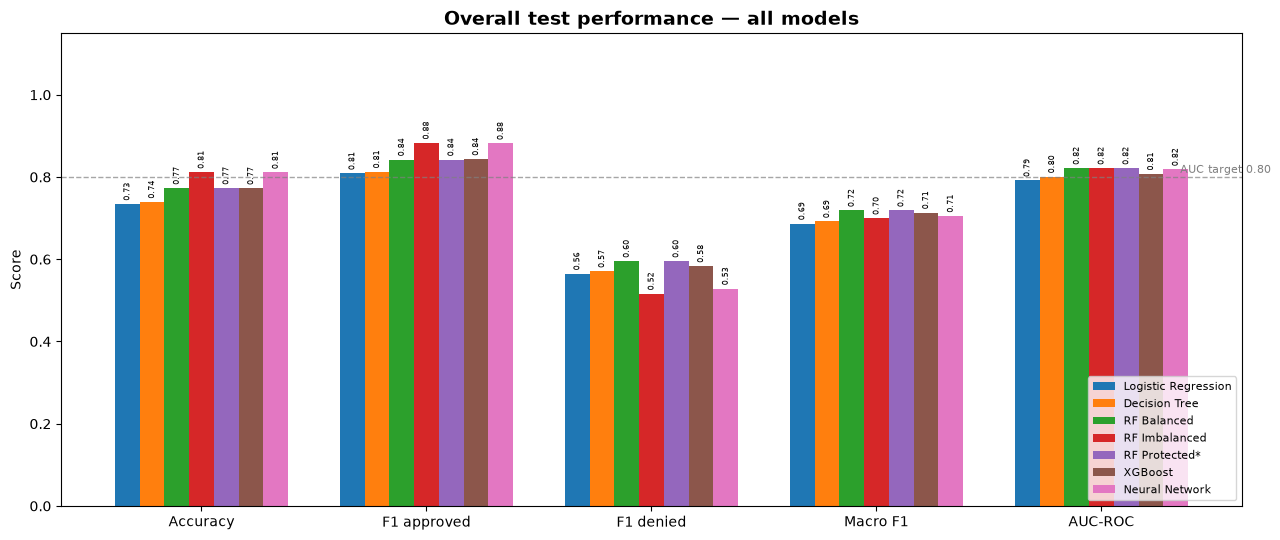

In [7]:
# Performance chart: side-by-side bars for every model
perf_cols = ['accuracy', 'f1_approved', 'f1_denied', 'macro_f1', 'auc_roc']
perf_labels = ['Accuracy', 'F1 approved', 'F1 denied', 'Macro F1', 'AUC-ROC']
x = np.arange(len(perf_labels))
width = 0.11
fig, ax = plt.subplots(figsize=(13, 5.5))
colors = plt.cm.tab10.colors

for i, (_, row) in enumerate(scorecard.iterrows()):
  vals = [row[c] for c in perf_cols]
  bars = ax.bar(x + (i - 3) * width, vals, width, label=row['model'], color=colors[i])
  for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.008, f'{v:.2f}',
            ha='center', va='bottom', fontsize=6, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(perf_labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title('Overall test performance — all models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.axhline(0.80, color='gray', ls='--', lw=1, alpha=0.7)
ax.text(4.35, 0.81, 'AUC target 0.80', fontsize=8, color='gray')
plt.tight_layout()
plt.show()


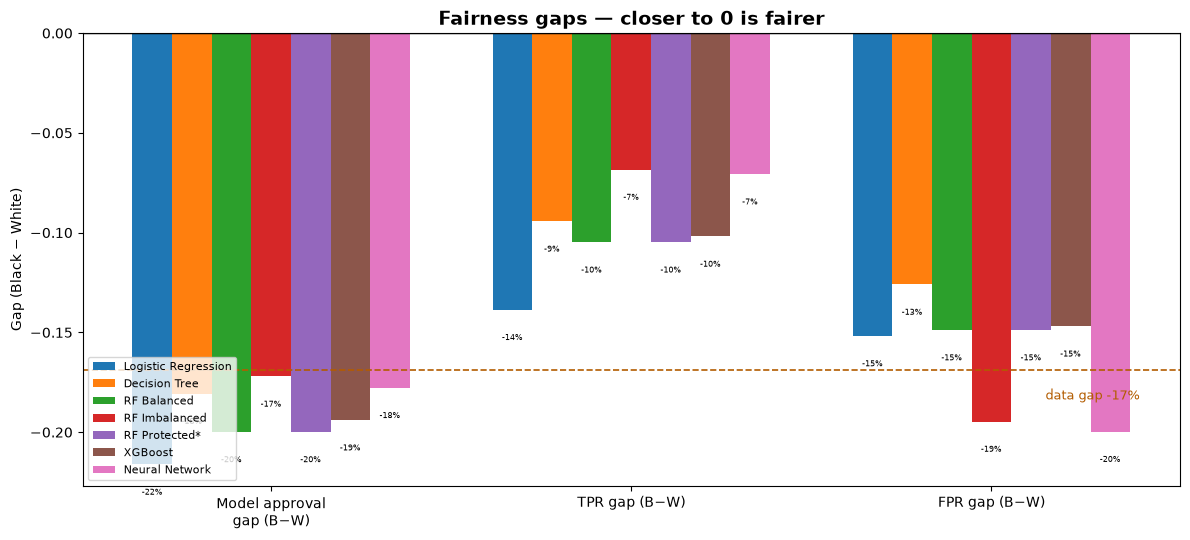

How to read this:
- Performance: higher is better. Prefer denied F1, macro F1, and AUC over approved F1.
- Fairness: closer to 0 is fairer. Dashed line = gap already in the data.
- Best pick: strong denied F1 / macro F1 / AUC without a much worse Black-White gap than the data.


In [8]:
# Fairness chart: Black-White gaps (closer to 0 is fairer)
fair_cols = ['pred_approval_gap', 'tpr_gap', 'fpr_gap']
fair_labels = ['Model approval\ngap (B−W)', 'TPR gap (B−W)', 'FPR gap (B−W)']
x = np.arange(len(fair_labels))
width = 0.11
fig, ax = plt.subplots(figsize=(12, 5.5))
colors = plt.cm.tab10.colors

for i, (_, row) in enumerate(scorecard.iterrows()):
  vals = [row[c] for c in fair_cols]
  bars = ax.bar(x + (i - 3) * width, vals, width, label=row['model'], color=colors[i])
  for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v - 0.012 if v < 0 else v + 0.005,
            f'{v:+.0%}', ha='center', va='top' if v < 0 else 'bottom', fontsize=6)

true_gap = scorecard['true_approval_gap'].iloc[0]
ax.axhline(0, color='black', lw=1)
ax.axhline(true_gap, color='#B35C00', ls='--', lw=1.2)
ax.text(2.15, true_gap - 0.015, f'data gap {true_gap:+.0%}', color='#B35C00', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(fair_labels)
ax.set_ylabel('Gap (Black − White)')
ax.set_title('Fairness gaps — closer to 0 is fairer', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

print('How to read this:')
print('- Performance: higher is better. Prefer denied F1, macro F1, and AUC over approved F1.')
print('- Fairness: closer to 0 is fairer. Dashed line = gap already in the data.')
print('- Best pick: strong denied F1 / macro F1 / AUC without a much worse Black-White gap than the data.')
